### All imports

In [2]:
import numpy as np

from sympy import symbols, rad, solve, lambdify, Matrix, matrix2numpy
from sympy.physics.mechanics import ReferenceFrame, dynamicsymbols

from scipy.integrate import odeint

from matplotlib import pyplot as plt

from matplotlib.animation import FFMpegWriter
from IPython.display import Image

### Kinematics

In [3]:
x_1, x_2, theta = dynamicsymbols('x_1, x_2, theta')
u_1, u_2 = symbols('u_1, u_2')

N = ReferenceFrame('N')

B = N.orientnew('B', 'Axis', (theta, N.z))
M = B.orientnew('M', 'Axis', (rad(90) + u_2, B.z))

xipos = x_1*N.x + x_2*N.y
xivel = xipos.dt(N)
xiacc = xivel.dt(N)

### Kinetics

In [4]:
m, l, c = symbols('m, l, c')

sumF = u_1*M.x -c*(xivel) -0*m*9.81*N.y - m*xiacc

sumM = (-l/2*B.y).cross(u_1*M.x) -c*theta.diff()*B.z - m*l**2/12*theta.diff().diff()*B.z


In [5]:
sumFx = sumF.dot(N.x)
sumFy = sumF.dot(N.y)
sumMz = sumM.dot(N.z)

eqs = [sumFx, sumFy, sumMz]
vars = [x_1.diff().diff(), x_2.diff().diff(), theta.diff().diff()]

slns = solve(eqs, vars)

acc = Matrix( [ slns[x_1.diff().diff()], slns[x_2.diff().diff()], slns[theta.diff().diff()] ] )
acc.simplify()

In [9]:
acc[0].simplify()

-(c*Derivative(x_1(t), t) + u_1*sin(u_2 + theta(t)))/m

Matrix([[x + 1, 0]])

In [ ]:
params = {c: 3, m: 5, l:1}
xddot = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()], u_1, u_2], acc.subs(params), 'numpy')

In [ ]:
xddot([0,0,0, 0,0,0], 1, 0).squeeze()

array([-0. ,  0.2, -0. ])

### ODE Solution

In [ ]:
def odefun(q, t, u_1, u_2):
  qdot = np.zeros_like(q)
  qdot[:3] = q[3:]
  qdot[3:] = xddot(q, u_1, u_2).squeeze()
  return qdot

In [ ]:
dt = 1/100
time = np.arange(0, 10, dt)
q0 = np.array([0, 0, 0, 0, 0, 0])

q_list = odeint(odefun, q0, time, args=(36, np.deg2rad(0)))

In [ ]:
def makeAnimation(qq, dt, filename='anim.gif', FPS=24, dpi=80, window_size=10):
  xipos_x = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()]], xipos.dot(N.x).subs(params))
  xipos_y = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()]], xipos.dot(N.y).subs(params))

  motor_pos_x = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()]], (xipos -l/2*B.y).dot(N.x).subs(params))
  motor_pos_y = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()]], (xipos -l/2*B.y).dot(N.y).subs(params))

  fig, ax = plt.subplots()
  com = ax.scatter([], [], label='com')
  motor = ax.scatter([],[], label='motor')

  ax.grid()
  ax.legend()
  ax.set_xlim(-window_size, window_size)
  ax.set_ylim(-window_size, window_size)
  ax.set_aspect('equal')

  ax.set(xlabel='$x$ Axis ($m$)', ylabel='$y$ Axis ($m$)')


  sample_rate = int(1/(dt*FPS))
  writer = FFMpegWriter(fps=FPS)

  with writer.saving(fig, filename, dpi):
    for i in range(0, len(qq), sample_rate):

      com.set_offsets([[xipos_x(qq[i]), xipos_y(qq[i])]])
      motor.set_offsets([[motor_pos_x(qq[i]), motor_pos_y(qq[i])]])

      fig.canvas.draw()
      writer.grab_frame()

  plt.close(fig)

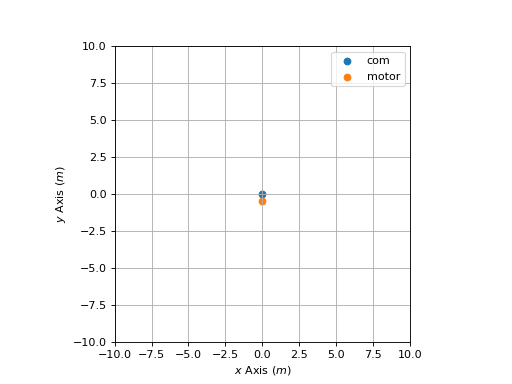

In [ ]:
makeAnimation(q_list, dt)

gif_display = Image(filename='anim.gif')
display(gif_display)

### PID

In [ ]:
def odefun2(q, t, q_ref, Kp=2, Kd=2, Kp_theta=10, Kd_theta=2):
  qdot = np.zeros_like(q)
  qdot[:3] = q[3:]


  if t>7.5:
    q_ref[0] = -2.5
    q_ref[1] = -2.5


  Fx = Kp*(q_ref[0] - q[0]) + Kd*(q_ref[3] - q[3])
  Fy = Kp*(q_ref[1] - q[1]) + Kd*(q_ref[4] - q[4]) + 0*5*9.81

  #Outer Loop
  thrust_des = np.sqrt(Fx**2 + Fy**2)
  theta_des = np.arctan2(Fy, Fx) - np.pi/2

  #Inner Loop
  torque_des = Kp_theta*(theta_des - q[2]) + Kd_theta*(q_ref[5] - q[5])


  u_2 =  np.arcsin(-2*np.clip(torque_des, a_min=-thrust_des*(params[l]/2), a_max=thrust_des*(params[l]/2))/(params[l]*thrust_des))


  u_1 = np.clip(thrust_des, a_min=0, a_max=10)



  qdot[3:] = xddot(q, u_1, u_2).squeeze()
  return qdot

In [ ]:
dt = 1/1000
time = np.arange(0, 15, dt)
q0 = np.array([0, 0, 0, 0, 0, 0])

q_ref = np.array([5, 5, 0, 0, 0, 0])

q_list = odeint(odefun2, q0, time, args=(q_ref,))

In [ ]:
def makeAnimation2(qq, dt, filename='anim.gif', FPS=24, dpi=80, window_size=10):
  xipos_x = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()]], xipos.dot(N.x).subs(params))
  xipos_y = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()]], xipos.dot(N.y).subs(params))

  motor_pos_x = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()]], (xipos -l/2*B.y).dot(N.x).subs(params))
  motor_pos_y = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()]], (xipos -l/2*B.y).dot(N.y).subs(params))

  fig, ax = plt.subplots()
  com = ax.scatter([], [], label='com')
  motor = ax.scatter([],[], label='motor')

  ax.scatter([-2.5, 5],[-2.5, 5],label='reference points')

  ax.grid()
  ax.legend()
  ax.set_xlim(-window_size, window_size)
  ax.set_ylim(-window_size, window_size)
  ax.set_aspect('equal')

  ax.set(xlabel='$x$ Axis ($m$)', ylabel='$y$ Axis ($m$)')


  sample_rate = int(1/(dt*FPS))
  writer = FFMpegWriter(fps=FPS)

  with writer.saving(fig, filename, dpi):
    for i in range(0, len(qq), sample_rate):

      com.set_offsets([[xipos_x(qq[i]), xipos_y(qq[i])]])
      motor.set_offsets([[motor_pos_x(qq[i]), motor_pos_y(qq[i])]])

      fig.canvas.draw()
      writer.grab_frame()

  plt.close(fig)

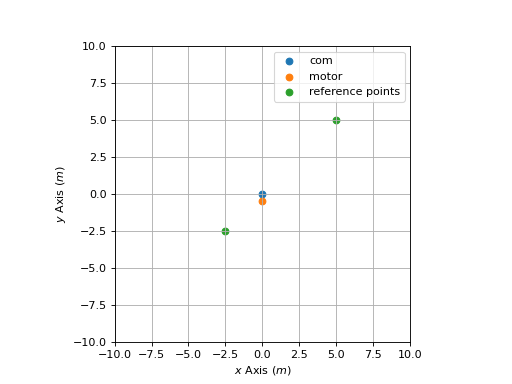

In [ ]:
makeAnimation2(q_list, dt, window_size=10)

gif_display = Image(filename='anim.gif')
display(gif_display)